Finite-mean limit:      pi_1 = 0.333333
Equal-exponent limit:   pi_1 = 0.659073
Unequal-exponent limit: pi_1 = 1.000000


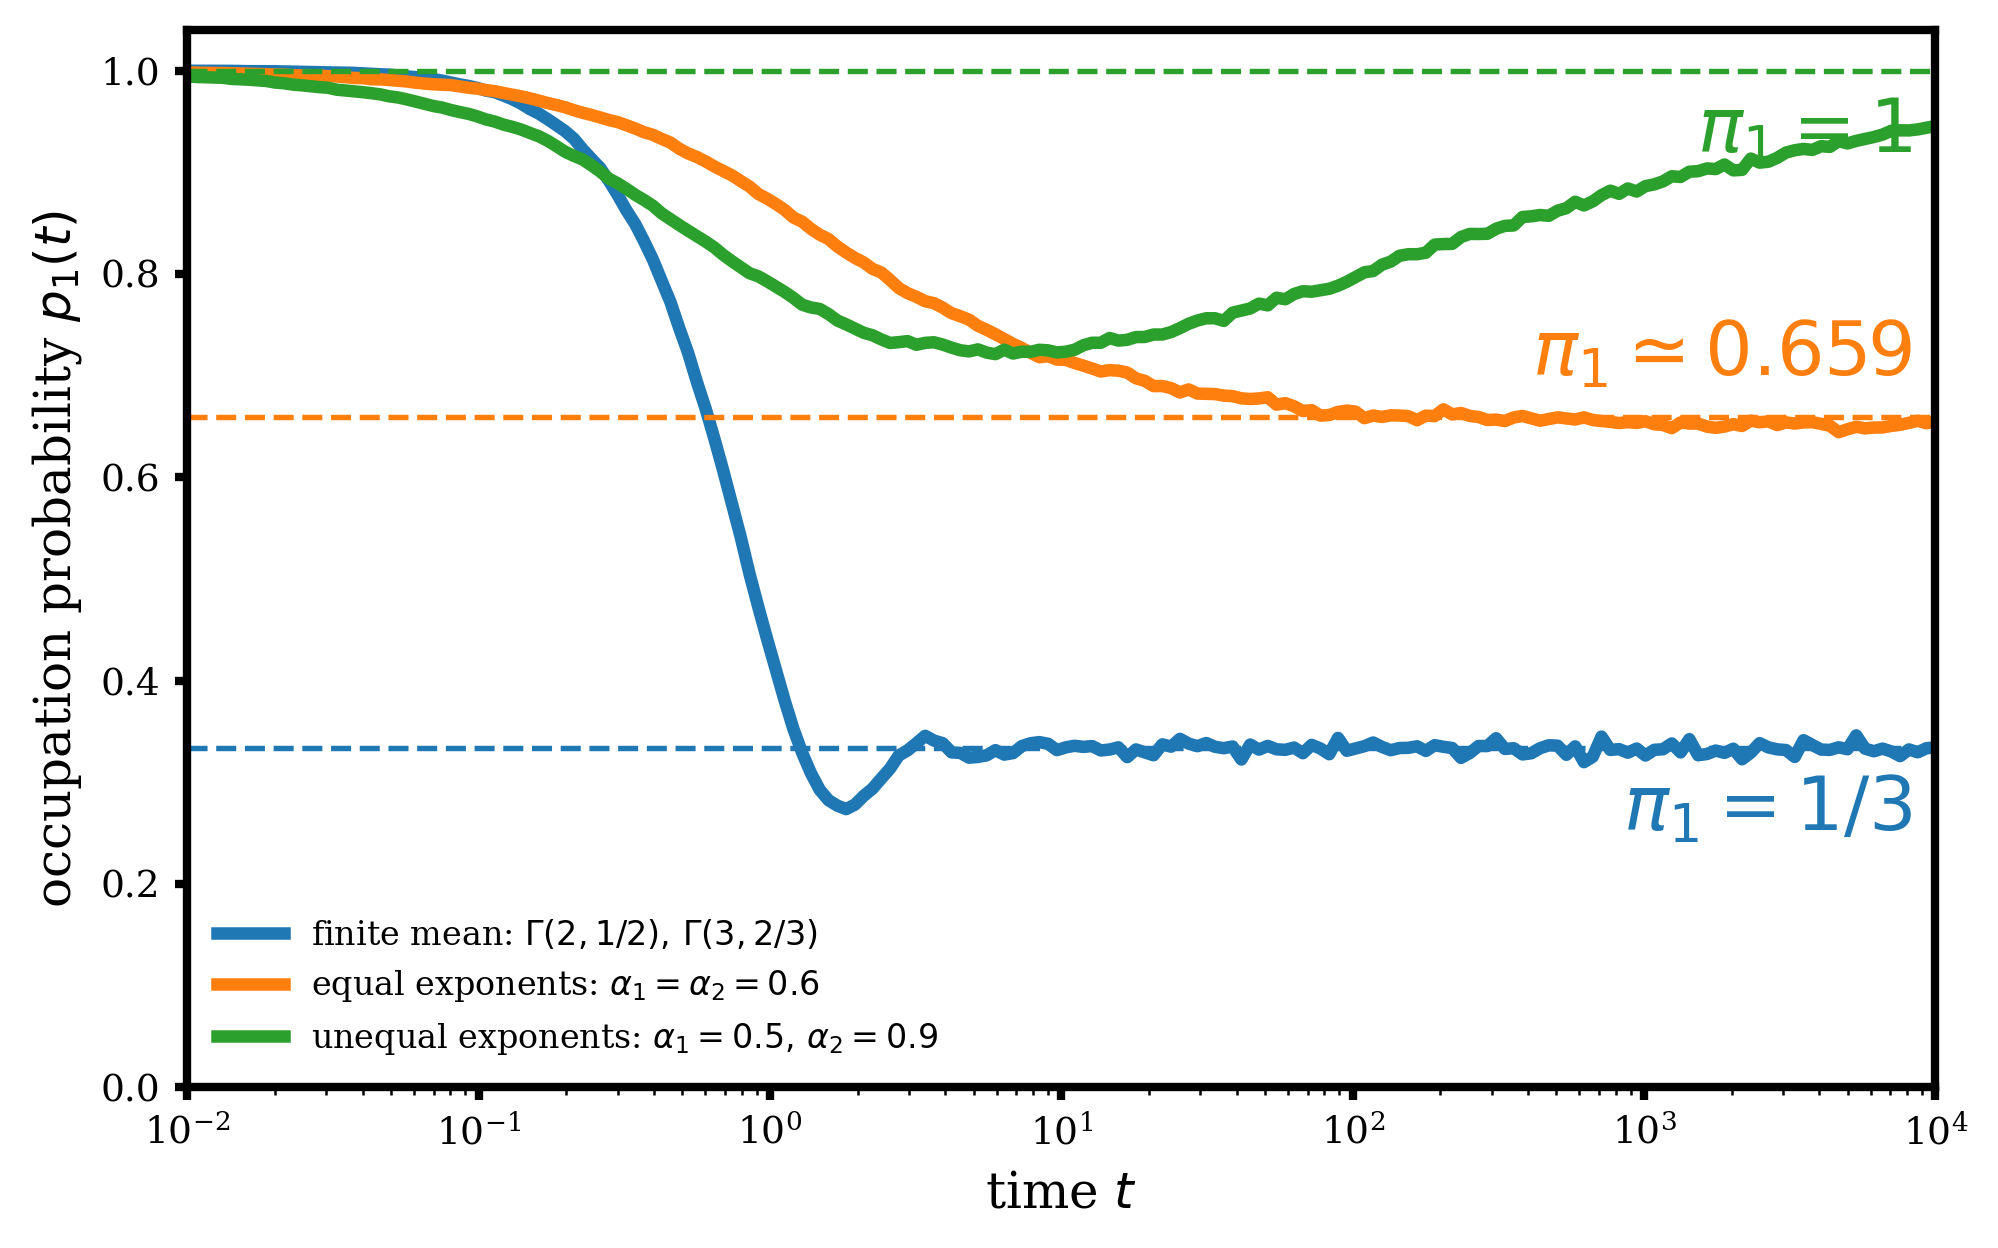

In [2]:
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 18,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "lines.linewidth": 3,
    "lines.markersize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "axes.grid": False,
    "grid.linestyle": "--",
    "grid.color": "0.8",
    "grid.linewidth": 0.5,
    "axes.linewidth": 2,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})


# ------------------------------------------------------------
# Waiting-time samplers
# ------------------------------------------------------------

def sample_pareto_ii(rng, alpha, scale):
    r"""
    Pareto-II waiting time with survival function

        P(T > t) = (1 + t / scale)^(-alpha).

    For 0 < alpha < 1,

        1 - Q_tilde(s)
        ~ Gamma(1 - alpha) * scale**alpha * s**alpha.
    """
    if not 0.0 < alpha < 1.0:
        raise ValueError("For the heavy-tailed cases, alpha must lie in (0, 1).")

    if scale <= 0.0:
        raise ValueError("The scale must be positive.")

    u = rng.random()
    u = max(u, np.finfo(float).tiny)

    return scale * (u ** (-1.0 / alpha) - 1.0)


def sample_gamma(rng, shape, scale):
    """
    Gamma waiting time in the shape-scale convention.

    Mean = shape * scale.
    """
    if shape <= 0.0 or scale <= 0.0:
        raise ValueError("Gamma shape and scale must be positive.")

    return rng.gamma(shape=shape, scale=scale)


# ------------------------------------------------------------
# Monte Carlo estimator
# ------------------------------------------------------------

def estimate_two_state_probability(
    observation_times,
    n_trajectories,
    sampler_1,
    sampler_2,
    seed=123456,
):
    """
    Estimate

        p_1(t) = P(X_t = 1)

    for an alternating two-state semi-Markov process

        1 -> 2 -> 1 -> 2 -> ...

    started in state 1.

    Parameters
    ----------
    observation_times : array-like
        Increasing nonnegative observation times.
    n_trajectories : int
        Number of independent trajectories.
    sampler_1, sampler_2 : callable
        Functions of the form sampler(rng) returning a waiting time.
    seed : int
        Seed for the random-number generator.
    """
    observation_times = np.asarray(observation_times, dtype=float)

    if observation_times.ndim != 1:
        raise ValueError("observation_times must be one-dimensional.")

    if observation_times.size == 0:
        raise ValueError("observation_times must not be empty.")

    if np.any(observation_times < 0.0):
        raise ValueError("Observation times must be nonnegative.")

    if np.any(np.diff(observation_times) < 0.0):
        raise ValueError("Observation times must be sorted.")

    if n_trajectories <= 0:
        raise ValueError("n_trajectories must be positive.")

    rng = np.random.default_rng(seed)

    t_max = observation_times[-1]
    state_1_counts = np.zeros(observation_times.size, dtype=np.int64)

    for _ in range(n_trajectories):
        jump_times = []
        current_time = 0.0
        state = 1

        while current_time <= t_max:
            if state == 1:
                waiting_time = sampler_1(rng)
            else:
                waiting_time = sampler_2(rng)

            if not np.isfinite(waiting_time) or waiting_time < 0.0:
                raise ValueError(
                    "The waiting-time samplers must return finite "
                    "nonnegative values."
                )

            # A zero waiting time would prevent time from advancing.
            if waiting_time == 0.0:
                waiting_time = np.nextafter(0.0, 1.0)

            current_time += waiting_time
            jump_times.append(current_time)

            state = 2 if state == 1 else 1

        jump_times = np.asarray(jump_times)

        # Number of transitions completed by each observation time.
        number_of_jumps = np.searchsorted(
            jump_times,
            observation_times,
            side="right",
        )

        # Starting from state 1:
        # even number of jumps -> state 1;
        # odd number of jumps  -> state 2.
        state_1_counts += number_of_jumps % 2 == 0

    return state_1_counts / n_trajectories


# ------------------------------------------------------------
# General simulation parameters
# ------------------------------------------------------------

n_trajectories = 10_000 #paper used 10^5
positive_times = np.logspace(-2, 4, 200) #paper used (-2, 5, 200)
times = np.concatenate(([0.0], positive_times))


# ------------------------------------------------------------
# Regime I:
# finite-mean, genuinely semi-Markov gamma waiting times
# ------------------------------------------------------------

shape_1 = 2.0
scale_1_gamma = 0.5

shape_2 = 3.0
scale_2_gamma = 2.0 / 3.0

mu_1 = shape_1 * scale_1_gamma
mu_2 = shape_2 * scale_2_gamma

pi_1_finite = mu_1 / (mu_1 + mu_2)

p_1_finite = estimate_two_state_probability(
    observation_times=times,
    n_trajectories=n_trajectories,
    sampler_1=lambda rng: sample_gamma(
        rng,
        shape=shape_1,
        scale=scale_1_gamma,
    ),
    sampler_2=lambda rng: sample_gamma(
        rng,
        shape=shape_2,
        scale=scale_2_gamma,
    ),
    seed=24680,
)


# ------------------------------------------------------------
# Regime II:
# equal heavy-tail exponents, different tail amplitudes
# ------------------------------------------------------------

alpha_equal = 0.6
scale_1_equal = 3.0
scale_2_equal = 1.0

p_1_equal = estimate_two_state_probability(
    observation_times=times,
    n_trajectories=n_trajectories,
    sampler_1=lambda rng: sample_pareto_ii(
        rng,
        alpha=alpha_equal,
        scale=scale_1_equal,
    ),
    sampler_2=lambda rng: sample_pareto_ii(
        rng,
        alpha=alpha_equal,
        scale=scale_2_equal,
    ),
    seed=31425,
)

# For Pareto-II waiting times,
#
#   a_i = Gamma(1 - alpha) * scale_i**alpha.
#
# The common Gamma factor cancels for equal alpha.
pi_1_equal = (
    scale_1_equal ** alpha_equal
    / (
        scale_1_equal ** alpha_equal
        + scale_2_equal ** alpha_equal
    )
)


# ------------------------------------------------------------
# Regime III:
# unequal heavy-tail exponents
# ------------------------------------------------------------

alpha_1_unequal = 0.5
alpha_2_unequal = 0.9

scale_1_unequal = 1.0
scale_2_unequal = 1.0

p_1_unequal = estimate_two_state_probability(
    observation_times=times,
    n_trajectories=n_trajectories,
    sampler_1=lambda rng: sample_pareto_ii(
        rng,
        alpha=alpha_1_unequal,
        scale=scale_1_unequal,
    ),
    sampler_2=lambda rng: sample_pareto_ii(
        rng,
        alpha=alpha_2_unequal,
        scale=scale_2_unequal,
    ),
    seed=93640,
)

# State 1 has the smaller exponent and therefore the heavier tail.
pi_1_unequal = 1.0


# ------------------------------------------------------------
# Print theoretical limiting probabilities
# ------------------------------------------------------------

print(f"Finite-mean limit:      pi_1 = {pi_1_finite:.6f}")
print(f"Equal-exponent limit:   pi_1 = {pi_1_equal:.6f}")
print(f"Unequal-exponent limit: pi_1 = {pi_1_unequal:.6f}")


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7.0, 4.5))

line_finite, = ax.plot(
    positive_times,
    p_1_finite[1:],
    label=(
        r"finite mean: "
        r"$\Gamma(2,1/2),\,\Gamma(3,2/3)$"
    ),
)

line_equal, = ax.plot(
    positive_times,
    p_1_equal[1:],
    label=(
        r"equal exponents: "
        r"$\alpha_1=\alpha_2=0.6$"
    ),
)

line_unequal, = ax.plot(
    positive_times,
    p_1_unequal[1:],
    label=(
        r"unequal exponents: "
        rf"$\alpha_1={alpha_1_unequal},\,"
        rf"\alpha_2={alpha_2_unequal}$"
    ),
)

# Exact limiting values
ax.axhline(
    pi_1_finite,
    color=line_finite.get_color(),
    linestyle="--",
    linewidth=1.3,
)

ax.axhline(
    pi_1_equal,
    color=line_equal.get_color(),
    linestyle="--",
    linewidth=1.3,
)

ax.axhline(
    pi_1_unequal,
    color=line_unequal.get_color(),
    linestyle="--",
    linewidth=1.3,
)

ax.set_xscale("log")
ax.set_xlim(positive_times[0], positive_times[-1])
ax.set_ylim(0.0, 1.04)

ax.set_xlabel(r"time $t$")
ax.set_ylabel(r"occupation probability $p_1(t)$")

ax.legend(
    frameon=False,
    loc="best",
)

# Labels for theoretical limits
x_label = positive_times[-1] / 1.2

ax.text(
    x_label,
    pi_1_finite - 0.025,
    r"$\pi_1=1/3$",
    color=line_finite.get_color(),
    ha="right",
    va="top",
)

ax.text(
    x_label,
    pi_1_equal + 0.025,
    rf"$\pi_1\simeq {pi_1_equal:.3f}$",
    color=line_equal.get_color(),
    ha="right",
    va="bottom",
)

ax.text(
    x_label,
    pi_1_unequal - 0.025,
    r"$\pi_1=1$",
    color=line_unequal.get_color(),
    ha="right",
    va="top",
)

fig.tight_layout()

fig.savefig(
    "two_state_semimarkov_regimes.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "two_state_semimarkov_regimes.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

In [22]:
import csv

csv_filename = "two_state_semimarkov_data.csv"

with open(csv_filename, mode="w", newline="", encoding="utf-8") as csv_file:
    writer = csv.writer(csv_file)

    # Header row
    writer.writerow([
        "time",
        "p1_finite_gamma",
        "p1_equal_exponents",
        "p1_unequal_exponents",
        "pi1_finite_gamma",
        "pi1_equal_exponents",
        "pi1_unequal_exponents",
    ])

    # One row for each observation time
    for t, p_finite, p_equal, p_unequal in zip(
        times,
        p_1_finite,
        p_1_equal,
        p_1_unequal,
    ):
        writer.writerow([
            t,
            p_finite,
            p_equal,
            p_unequal,
            pi_1_finite,
            pi_1_equal,
            pi_1_unequal,
        ])

print(f"Data saved to {csv_filename}")

Data saved to two_state_semimarkov_data.csv


#### 